# 71 — Learned dynamics and model-predictive control

Model-free reinforcement learning learns behavior without explicitly predicting the next state. Model-based methods instead use a dynamics model to ask: *if I take this action, what will happen next?*

In this notebook we collect transitions from a small one-dimensional point mass, fit a linear approximation to its mildly nonlinear dynamics, and use that learned model for model-predictive control (MPC). The system is intentionally small so that prediction, planning, model error, and replanning remain visible.

## Learning goals

- Represent dynamics as a transition from $(s_t,a_t)$ to $s_{t+1}$.
- Collect a supervised transition dataset.
- Fit and evaluate a simple learned dynamics model.
- Distinguish one-step prediction error from accumulated rollout error.
- Plan by evaluating candidate action sequences through the model.
- Understand why MPC executes one action and then replans.
- Compare open-loop execution with closed-loop replanning after a disturbance.

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np

SEED = 42

## 1. A small controlled dynamical system

The experiment has one spatial dimension: the mass can move only left or right along a line. Its state is $s_t=(x_t,v_t)$, containing horizontal position and horizontal velocity. These are two state variables, not two spatial coordinates; velocity is needed because two objects at the same position can move in opposite directions. The scalar action $a_t\in[-1,1]$ is a bounded acceleration command: positive accelerates right, negative accelerates left, and zero adds no acceleration. The environment updates velocity first and then position:

$$
v_{t+1}=d v_t+\Delta t\,a_t-cv_t|v_t|,
$$

$$
x_{t+1}=x_t+\Delta t\,v_{t+1}.
$$

The three velocity terms have different roles:

- $d v_t$ retains the current motion. With $d=0.96$, the system keeps 96% of its velocity each step, representing mild linear energy loss.
- $\Delta t\,a_t$ converts the acceleration command into a velocity change over one time interval. Positive actions accelerate to the right and negative actions accelerate to the left.
- $-cv_t|v_t|$ is quadratic drag. The magnitude grows with speed squared and its sign always opposes motion. If $v_t>0$, the term is negative; if $v_t<0$, then $v_t|v_t|<0$ and subtracting it produces a positive force that makes the negative velocity less negative.

Quadratic drag is a simplified model of resistance from air or water, such as aerodynamic resistance on a vehicle. It is not essential for MPC; we include it because it gives the environment a small, physically interpretable nonlinearity. Without it, these dynamics would be affine and the linear model fitted later could reproduce them almost exactly. Here $c$ acts as a discrete-time drag coefficient; a more detailed physical derivation might include $\Delta t$ explicitly in this term too.

After calculating velocity, we update position using $v_{t+1}$ rather than $v_t$. This simple semi-implicit update first changes the velocity and then moves the object using that new velocity.

In [13]:
@dataclass
class PointMass1D:
    time_step: float = 0.2
    damping: float = 0.96
    drag: float = 0.1
    action_limit: float = 1.0

    def __post_init__(self):
        self.state = np.zeros(2, dtype=np.float64)

    def reset(self, state=(-2.0, 0.0)):
        self.state = np.asarray(state, dtype=np.float64).copy()
        return self.state.copy()

    def step(self, action):
        # A physical actuator cannot exceed its allowed acceleration range.
        action = float(np.clip(action, -self.action_limit, self.action_limit))
        position, velocity = self.state

        # Retain damped motion, add action-induced acceleration, and subtract
        # quadratic drag. velocity * abs(velocity) preserves the direction,
        # so the leading minus sign makes drag oppose either direction.
        next_velocity = (
            self.damping * velocity
            + self.time_step * action
            - self.drag * velocity * abs(velocity)
        )

        # Move for one time interval using the newly calculated velocity.
        next_position = position + self.time_step * next_velocity
        self.state = np.array([next_position, next_velocity])
        return self.state.copy()


environment = PointMass1D()
print("initial state:", environment.reset())
print("after action +1:", environment.step(1.0))

initial state: [-2.  0.]
after action +1: [-1.96  0.2 ]


## 2. Learn dynamics from transitions

A transition model predicts

$$
\hat{s}_{t+1}=f_\theta(s_t,a_t).
$$

This becomes a supervised-learning problem: the current state and action form the input, while the state observed after executing the action is the target. Random initial states and actions give the model broader coverage than repeatedly following one trajectory.

### Exercise 1 — Collect a transition dataset

In [14]:
def collect_transition_data(number_transitions, rng):
    environment = PointMass1D()
    states = np.empty((number_transitions, 2))
    actions = np.empty((number_transitions, 1))
    next_states = np.empty((number_transitions, 2))

    for index in range(number_transitions):
        state = np.array([rng.uniform(-3.0, 3.0), rng.uniform(-1.5, 1.5)])
        action = rng.uniform(-1.0, 1.0)
        environment.reset(state)
        # execute the action and store (state, action, next_state).
        next_state = environment.step(action)

        states[index] = state
        actions[index, 0] = action
        next_states[index] = next_state

    return states, actions, next_states


states, actions, next_states = collect_transition_data(2_000, np.random.default_rng(SEED))
print(states.shape, actions.shape, next_states.shape)
assert states.shape == (2_000, 2)
assert actions.shape == (2_000, 1)
assert next_states.shape == (2_000, 2)

(2000, 2) (2000, 1) (2000, 2)


## 3. Fit a linear dynamics approximation

We model the next state as an affine function of state and action:

$$
\hat{s}_{t+1}=[x_t, v_t, a_t, 1]W.
$$

Each training row therefore contains four features: current position, current velocity, action, and a constant $1$. For $N$ transitions, the feature matrix has shape $(N,4)$ and the target next states have shape $(N,2)$. The weight matrix must consequently have shape $(4,2)$:

$$
(N,4)(4,2)=(N,2).
$$

The two output columns learn separate affine equations for next position and next velocity. The final constant feature supplies their intercepts. NumPy's least-squares solver directly finds $W$ that minimizes the total squared one-step prediction error over the training transitions; unlike neural-network training, this small linear problem needs no epoch or gradient-descent loop.

The model is still only an approximation. The environment contains the nonlinear feature $v_t|v_t|$, but the learned input contains only $x_t$, $v_t$, $a_t$, and $1$. Least squares therefore finds the best linear fit over the sampled data range rather than recovering the true drag equation exactly.

### Exercise 2 — Fit and use the learned model

In [15]:
@dataclass
class LinearDynamicsModel:
    weights: np.ndarray

    def predict(self, states, actions):
        states = np.asarray(states, dtype=np.float64)
        actions = np.asarray(actions, dtype=np.float64)
        # A single state arrives as shape (2,). Add a batch axis so both
        # single and batched inputs use the common shape (N, 2).
        if states.ndim == 1:
            states = states[None, :]

        # One scalar action has shape (). Convert it to one row and one
        # action feature: (1, 1).
        if actions.ndim == 0:
            actions = actions.reshape(1, 1)
        # A batch of scalar actions usually has shape (N,). Add the feature
        # axis so it becomes (N, 1) and can be concatenated with states.
        elif actions.ndim == 1:
            actions = actions[:, None]
        features = np.concatenate(
            [states, actions, np.ones((len(states), 1))], axis=1
        )
        return features @ self.weights


def fit_linear_dynamics(states, actions, next_states):
    # concatenate state, action, and a constant feature.
    features = np.concatenate(
        [states, actions, np.ones((len(states), 1))], axis=1
    )
    # solve features @ weights approximately equal to next_states.
    weights = np.linalg.lstsq(features, next_states, rcond=None)[0]
    return LinearDynamicsModel(weights)


split_index = 1_600
model = fit_linear_dynamics(
    states[:split_index], actions[:split_index], next_states[:split_index]
)
test_predictions = model.predict(states[split_index:], actions[split_index:])
assert test_predictions.shape == next_states[split_index:].shape

## 4. One-step prediction error

One-step evaluation asks whether the model predicts the next observed state from a real current state. It does not yet test what happens when predictions are repeatedly fed back as inputs.

### Exercise 3 — Calculate per-dimension RMSE and visualize predictions

position RMSE, velocity RMSE: [0.00494702 0.02473511]


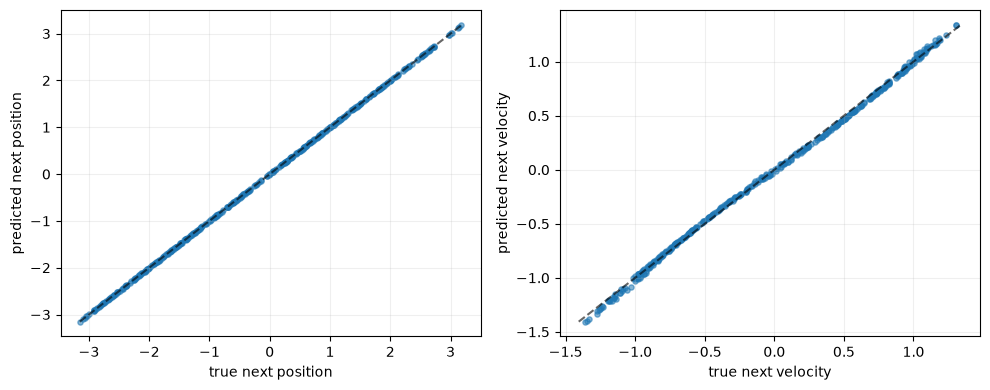

In [16]:
# calculate root mean squared error separately for position and velocity.
one_step_rmse = np.sqrt(np.mean((test_predictions - next_states[split_index:]) ** 2, axis=0))
print("position RMSE, velocity RMSE:", one_step_rmse)

figure, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ("next position", "next velocity")
for dimension, axis in enumerate(axes):
    axis.scatter(
        next_states[split_index:, dimension],
        test_predictions[:, dimension],
        s=14,
        alpha=0.55,
    )
    limits = [
        min(next_states[split_index:, dimension].min(), test_predictions[:, dimension].min()),
        max(next_states[split_index:, dimension].max(), test_predictions[:, dimension].max()),
    ]
    axis.plot(limits, limits, "k--", alpha=0.6)
    axis.set_xlabel(f"true {labels[dimension]}")
    axis.set_ylabel(f"predicted {labels[dimension]}")
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Multi-step rollout error

During planning, the model predicts from its own previous prediction. A small error changes the next input, which can create another error. This repeated feedback can make a long model rollout drift even when one-step RMSE is small.

### Exercise 4 — Compare real and learned rollouts

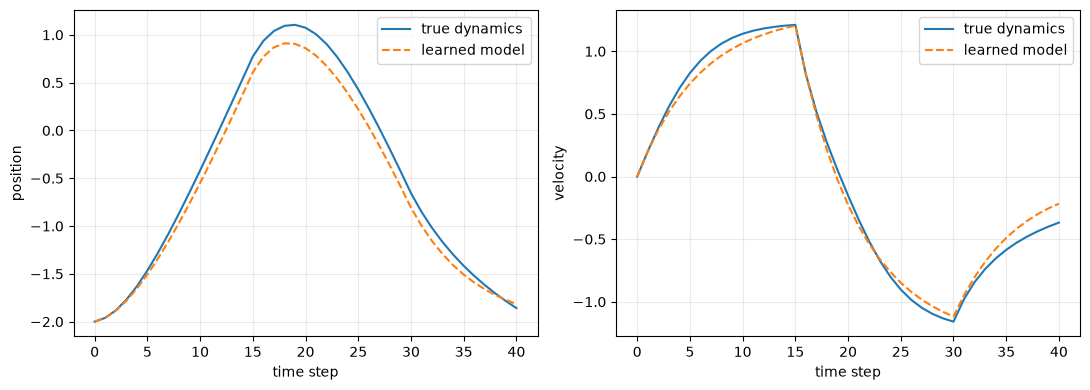

In [18]:
def compare_rollouts(model, initial_state, action_sequence):
    environment = PointMass1D()
    true_state = environment.reset(initial_state)
    model_state = np.asarray(initial_state, dtype=np.float64).copy()
    true_states = [true_state.copy()]
    model_states = [model_state.copy()]

    for action in action_sequence:
        # Advance the real environment from its internal true state.
        true_state = environment.step(action)
        # predict() uses a batch interface and returns shape (1, 2) for one
        # state-action pair. Select row 0 to keep model_state at shape (2,).
        model_state = model.predict(model_state, action)[0]
        true_states.append(true_state.copy())
        model_states.append(model_state.copy())

    return np.asarray(true_states), np.asarray(model_states)


rollout_actions = np.concatenate([np.ones(15), -np.ones(15), np.zeros(10)])
true_rollout, model_rollout = compare_rollouts(model, (-2.0, 0.0), rollout_actions)

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for dimension, label in enumerate(("position", "velocity")):
    axes[dimension].plot(true_rollout[:, dimension], label="true dynamics")
    axes[dimension].plot(model_rollout[:, dimension], "--", label="learned model")
    axes[dimension].set_xlabel("time step")
    axes[dimension].set_ylabel(label)
    axes[dimension].grid(alpha=0.25)
    axes[dimension].legend()
plt.tight_layout()
plt.show()

### Prediction is not yet control

Exercise 4 supplies a fixed action sequence deliberately. Its purpose is only to test the question: *given the same initial state and actions, how closely does the learned model reproduce the real system?* The dynamics model predicts consequences, $f_\theta(s,a)\rightarrow\hat{s}'$; it does not decide which action the robot should take.

The next sections add that missing decision process. A planner proposes many possible future action sequences, uses the learned model as an internal simulator, scores the predicted trajectories, and selects the action sequence with the lowest cost. MPC then executes only its first action, observes the real next state, and plans again.

## 6. Planning with the learned model

Planning evaluates possible futures without executing all of them in the real environment. Random shooting samples candidate action sequences, predicts their state sequences, assigns each a cost, and keeps the best candidate.

Our cost encourages positions near the target, a small final velocity, and moderate actions. Candidate actions are constant for short blocks so random sampling can discover coherent acceleration and braking patterns more easily than if every step were independent. For a 25-step horizon and block length 5, we sample only 5 action values and repeat each for 5 predicted steps. A block sequence such as $[+0.9,+0.7,+0.1,-0.6,-0.8]$ represents accelerate, coast, and brake phases, whereas 25 independently random actions would often alternate signs and cancel one another.

Block sampling reduces the random-search dimension from 25 independent values to 5, making useful candidates easier to find with a finite sample budget. The trade-off is less precise action timing. This restriction applies only inside one predicted plan: MPC still executes one real action and constructs an entirely new set of candidate sequences at the next step.

### Exercise 5 — Score candidate action sequences

In [20]:
def sample_action_sequences(number_candidates, horizon, block_length, rng):
    number_blocks = int(np.ceil(horizon / block_length))
    block_actions = rng.uniform(-1.0, 1.0, size=(number_candidates, number_blocks))
    return np.repeat(block_actions, block_length, axis=1)[:, :horizon]


def predict_action_sequences(model, initial_state, action_sequences):
    number_candidates, horizon = action_sequences.shape
    states = np.repeat(np.asarray(initial_state)[None, :], number_candidates, axis=0)
    predicted_states = np.empty((number_candidates, horizon + 1, 2))
    predicted_states[:, 0] = states
    for step in range(horizon):
        states = model.predict(states, action_sequences[:, step])
        predicted_states[:, step + 1] = states
    return predicted_states


def trajectory_cost(predicted_states, action_sequences, target_position):
    position_errors = predicted_states[:, 1:, 0] - target_position
    # Encourage the whole predicted trajectory to approach the target.
    running_position_cost = 0.05 * np.sum(position_errors**2, axis=1)
    # Discourage unnecessarily large acceleration commands.
    action_cost = 0.01 * np.sum(action_sequences**2, axis=1)
    # Strongly prefer ending near the target rather than merely passing it.
    terminal_position_cost = 5.0 * position_errors[:, -1] ** 2
    # Prefer arriving with low velocity so the mass does not overshoot.
    terminal_velocity_cost = 0.5 * predicted_states[:, -1, 1] ** 2
    costs = (
        running_position_cost
        + action_cost
        + terminal_position_cost
        + terminal_velocity_cost
    )
    return costs


candidate_actions = sample_action_sequences(2_000, 25, 5, np.random.default_rng(SEED))
candidate_states = predict_action_sequences(model, (-2.0, 0.0), candidate_actions)
candidate_costs = trajectory_cost(candidate_states, candidate_actions, target_position=2.0)
print("candidate cost shape:", candidate_costs.shape)
assert candidate_costs.shape == (2_000,)

candidate cost shape: (2000,)


The coefficients are hand-chosen planning hyperparameters, not values learned by the dynamics model. Terminal position receives the largest weight because reaching the target is the main objective; terminal velocity encourages arriving slowly, while action cost mildly discourages unnecessary acceleration. The running-position and action terms use small coefficients because each is summed across all 25 planned steps and can already become large. These exact values are not universal—they were selected to balance the typical term magnitudes and make the desired behavior visible in this experiment.

## 7. Model-predictive control

MPC repeatedly performs a short plan–act–observe loop:

1. observe the current real state;
2. plan several steps ahead with the model;
3. execute only the first action of the best sequence;
4. observe the actual next state and plan again.

Discarding the rest of the old plan may look wasteful, but the new observation corrects accumulated model error and allows the controller to respond to disturbances.

### Exercise 6 — Implement one MPC planning decision

In [ ]:
def select_mpc_action(
    model,
    state,
    target_position,
    rng,
    number_candidates=2_000,
    horizon=25,
    block_length=5,
):
    # sample sequences, predict them, calculate costs, and select the best.
    action_sequences = sample_action_sequences(number_candidates, horizon, block_length, rng)
    predicted_states = predict_action_sequences(model, state, action_sequences)
    costs = trajectory_cost(predicted_states, action_sequences, target_position)
    best_index = np.argmin(costs)
    return float(action_sequences[best_index, 0]), predicted_states[best_index], float(costs[best_index])


def run_mpc_controller(
    model,
    initial_state=(-2.0, 0.0),
    target_position=2.0,
    number_steps=35,
    disturbance_step=None,
    seed=SEED,
):
    environment = PointMass1D()
    state = environment.reset(initial_state)
    rng = np.random.default_rng(seed)
    states = [state.copy()]
    actions = []

    for step in range(number_steps):
        action, _, _ = select_mpc_action(model, state, target_position, rng)
        state = environment.step(action)
        if disturbance_step is not None and step == disturbance_step:
            environment.state[1] -= 1.0
            state = environment.state.copy()
        actions.append(action)
        states.append(state.copy())
    return np.asarray(states), np.asarray(actions)


mpc_states, mpc_actions = run_mpc_controller(model)
print("final MPC state:", mpc_states[-1])

final MPC state: [ 2.05474339 -0.07698021]


## 8. Open-loop plan versus replanning

An open-loop controller plans once and executes the complete action sequence without using new observations to revise it. MPC uses the same imperfect model but repeatedly anchors planning to the latest real state. We apply the same velocity disturbance to both controllers to make the difference visible.

### Exercise 7 — Compare responses to a disturbance

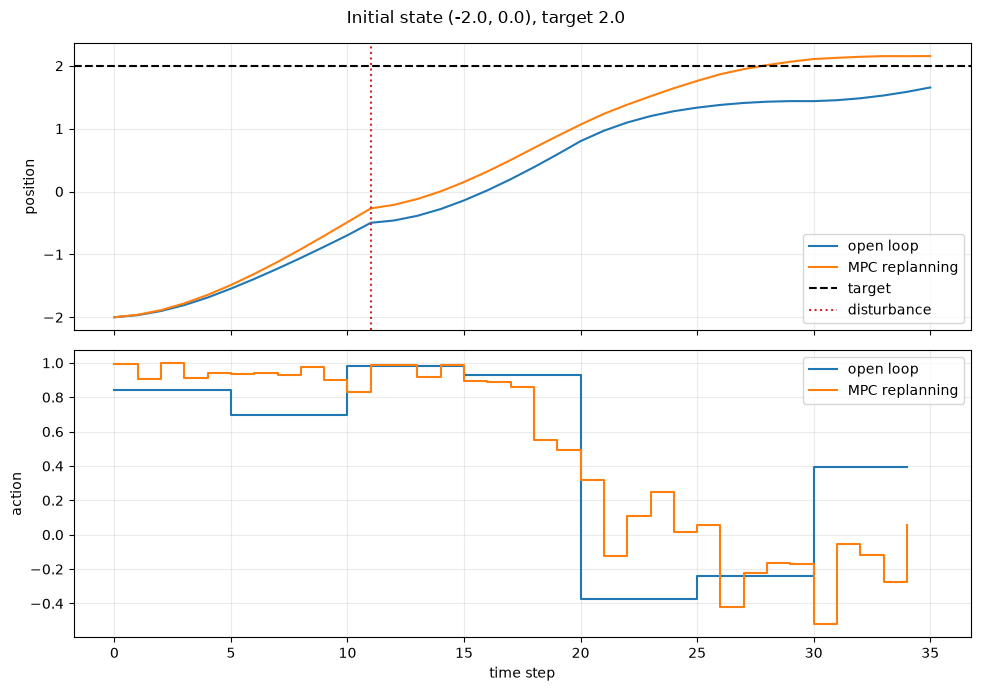

open-loop final position error: 0.34540783468959546
MPC final position error: 0.1543023922260418


In [33]:
def run_open_loop_controller(
    model,
    initial_state=(-2.0, 0.0),
    target_position=2.0,
    number_steps=35,
    disturbance_step=None,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    candidate_actions = sample_action_sequences(5_000, number_steps, 5, rng)
    candidate_states = predict_action_sequences(model, initial_state, candidate_actions)
    costs = trajectory_cost(candidate_states, candidate_actions, target_position)
    planned_actions = candidate_actions[np.argmin(costs)]

    environment = PointMass1D()
    state = environment.reset(initial_state)
    states = [state.copy()]
    for step, action in enumerate(planned_actions):
        state = environment.step(action)
        if disturbance_step is not None and step == disturbance_step:
            environment.state[1] -= 1.0
            state = environment.state.copy()
        states.append(state.copy())
    return np.asarray(states), planned_actions


def plot_controller_comparison(
    open_states,
    open_actions,
    replanned_states,
    replanned_actions,
    target_position,
    disturbance_step=None,
    title=None,
):
    """Plot position and action histories for open-loop and MPC control."""
    figure, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    axes[0].plot(np.arange(len(open_states)), open_states[:, 0], label="open loop")
    axes[0].plot(
        np.arange(len(replanned_states)),
        replanned_states[:, 0],
        label="MPC replanning",
    )
    axes[0].axhline(
        target_position, color="black", linestyle="--", label="target"
    )
    if disturbance_step is not None:
        # The disturbance is applied after this zero-indexed action step,
        # so its changed state appears at disturbance_step + 1.
        axes[0].axvline(
            disturbance_step + 1,
            color="tab:red",
            linestyle=":",
            label="disturbance",
        )
    axes[0].set_ylabel("position")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].step(
        np.arange(len(open_actions)),
        open_actions,
        where="post",
        label="open loop",
    )
    axes[1].step(
        np.arange(len(replanned_actions)),
        replanned_actions,
        where="post",
        label="MPC replanning",
    )
    axes[1].set_xlabel("time step")
    axes[1].set_ylabel("action")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    if title is not None:
        figure.suptitle(title)
    figure.tight_layout()
    return figure, axes

def run_experiment(
    initial_state=(-2.0, 0.0),
    target_position=2.0,
    number_steps=35,
    disturbance_step=10
):
    open_states, open_actions = run_open_loop_controller(
        model,
        initial_state=initial_state,
        target_position=target_position,
        number_steps=number_steps,
        disturbance_step=disturbance_step,
    )
    replanned_states, replanned_actions = run_mpc_controller(
        model,
        initial_state=initial_state,
        target_position=target_position,
        number_steps=number_steps,
        disturbance_step=disturbance_step,
    )

    plot_controller_comparison(
        open_states,
        open_actions,
        replanned_states,
        replanned_actions,
        target_position=target_position,
        disturbance_step=disturbance_step,
        title=f"Initial state {initial_state}, target {target_position}",
    )
    plt.show()

    print(
        "open-loop final position error:",
        abs(open_states[-1, 0] - target_position),
    )
    print(
        "MPC final position error:",
        abs(replanned_states[-1, 0] - target_position),
    )

run_experiment()

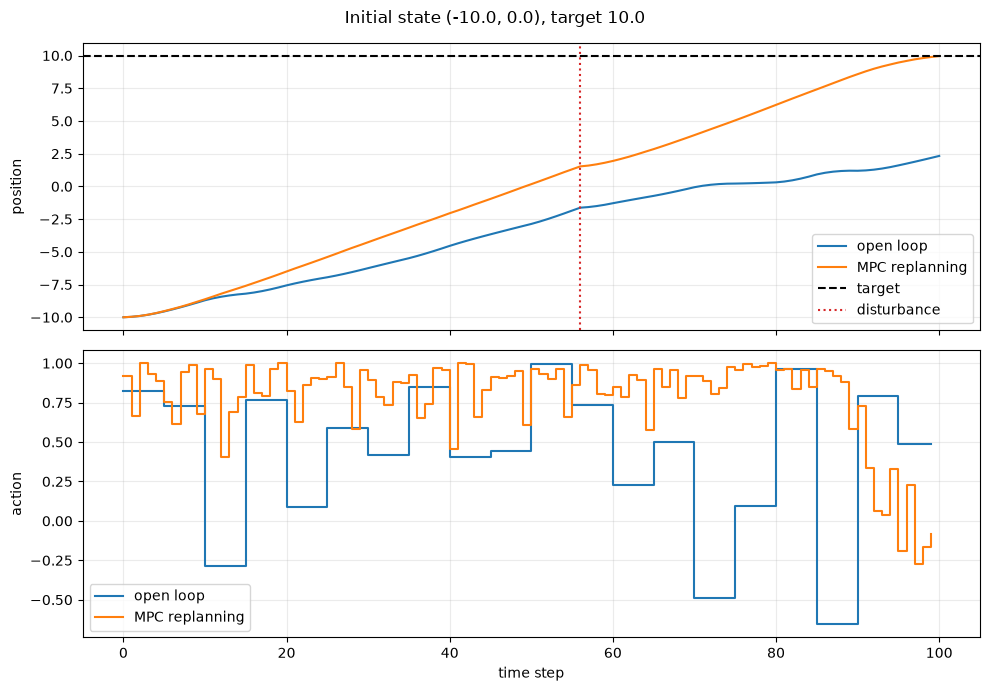

open-loop final position error: 7.672847837044068
MPC final position error: 0.04101471490157671


In [35]:
run_experiment(
    initial_state=(-10.0, 0.0),
    target_position=10.0,
    number_steps=100,
    disturbance_step=55,
)

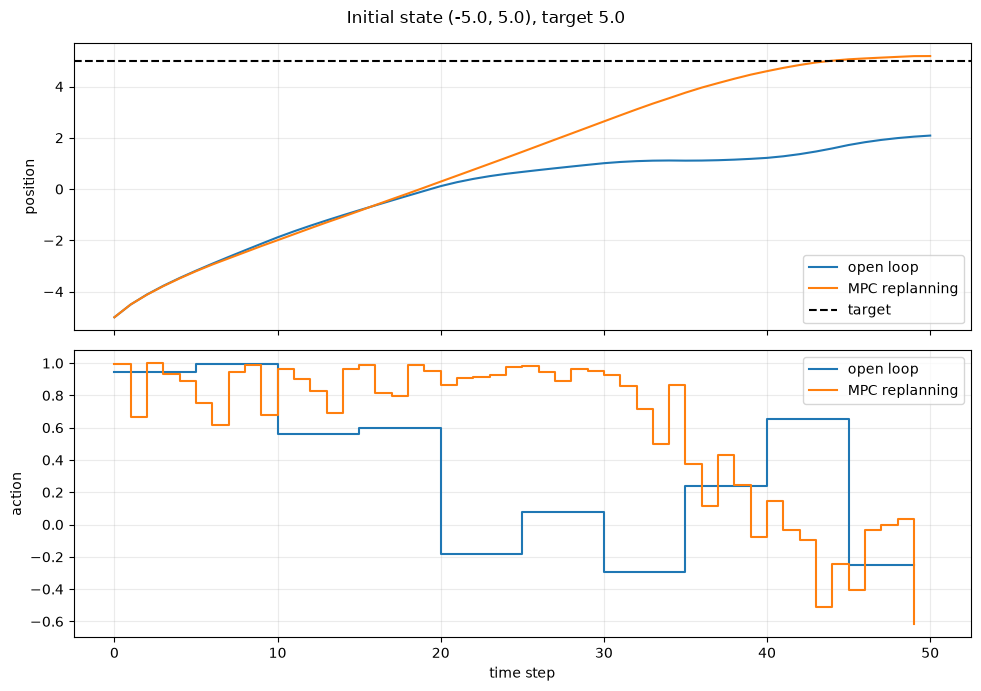

open-loop final position error: 2.9138543082439257
MPC final position error: 0.18746527175620464


In [36]:
run_experiment(
    initial_state=(-5.0, 5.0),
    target_position=5.0,
    number_steps=50,
    disturbance_step=None,
)

## 9. What the experiment teaches

A learned model can reduce real interaction by testing many hypothetical action sequences computationally. But planning quality is limited by model quality and by whether candidate actions keep predictions near the training distribution. Long imagined rollouts amplify error, which motivates short planning horizons and repeated replanning.

A basic two-dimensional extension would use state $(x,y,v_x,v_y)$, action $(a_x,a_y)$, a model with four outputs, and Euclidean position, velocity, and action costs. The learning and MPC logic would remain the same. The main difficulty is planning: every future step now contains two action values, so random shooting must search a much larger space and may require more candidates or a better optimizer. Obstacles and coupled physical effects would add further complexity.

Real robot MPC may use neural dynamics models, ensembles for uncertainty, more efficient optimizers, safety constraints, and high-dimensional observations. The core loop remains predict, choose, execute briefly, observe, and replan.

See [Learned dynamics, planning, and model-predictive control](../notes/17-robot-learning/learned-dynamics-planning-and-mpc.md) for a concise conceptual summary.

## Reflection

1. Why can learning dynamics be formulated as supervised learning?

   _Your answer:_

2. Why can a model have small one-step error but drift during a long rollout?

   _Your answer:_

3. What does random-shooting planning optimize, and what does it leave approximate?

   _Your answer:_

4. Why does MPC execute only the first action of its selected sequence?

   _Your answer:_

5. Why can replanning recover from a disturbance better than open-loop execution?

   _Your answer:_

6. What can go wrong when planning drives the learned model far outside its training distribution?

   _Your answer:_